# Background

## The basic pendulum



Let's start with the basic pendulum, a pivot which does not move and a single arm. We'll first find the equation of motion, a differential equation which when solved describes the motion of the object over time. Let's keep the shape of the pendulum general. Define the moment of inertia to be $I$, the mass to be $m$, the distance from the pivot to the center of mass to be $L$ and its angle to be $\theta$, where $\theta=0$ means that the pendulum is hanging downward. There are two methods to do this:

### Newtonian mechanics

About the pivot's axis, there is a torque
$$
\tau = L \cdot (-mg\sin\theta),
$$
and we know how torque relates to angular acceleration:
$$
I \ddot{\theta} = \tau .
$$
So out equation of motion is
$$
\ddot{\theta} + \frac{mL}{I} g \sin\theta = 0 .
$$
Note that if you assume the arm consists of only a point mass, $mL/I = 1/L$.

### Lagrangian mechanics

This method lets you not worry about forces, vectors, or free body diagrams. As long as you know the kinetic and potential energy, you can find the equation of motion.

The kinetic energy involved is the angular kinetic energy of the center of mass:
$$
T = \frac{1}{2}I\dot{\theta}^2
$$
and the potential energy comes from gravity, and we should express it with the same variable as in kinetic:
$$
V = mgy = -mgL\cos\theta .
$$

The Lagrangian is defined as $\mathcal{L} = T - V$. In our case,
$$
\mathcal{L} = \frac{1}{2}I\dot{\theta}^2 + mgL\cos\theta .
$$
To go from the Lagrangian to the equation of motion, we use the Euler-Lagrange equation for each degree of freedom $q_i$:
$$
\frac{d}{dt} \frac{\partial \mathcal{L}}{\partial \dot{q_i}} = \frac{\partial \mathcal{L}}{\partial q_i} .
$$
In our case, there's only one degree of freedom $\theta$. So we get
$$
\begin{aligned}
\frac{d}{dt} \frac{\partial \mathcal{L}}{\partial \dot{\theta}} &= \frac{\partial \mathcal{L}}{\partial \theta}
\\
\frac{d}{dt} I\dot\theta &= -mgL\sin\theta
\\
I\ddot\theta &= -mgL\sin\theta
\\
\ddot\theta &+ \frac{mL}{I} g \sin\theta = 0
\end{aligned}
$$
and we get the same answer! Because these numbers will always be bundled together, let's say $\frac{mL}{I} g = \mu$.

### Analyzing stability from the equation of motion

Even with such a simple equation of motion, we can't solve it analytically. However, we can still say something about its stability. First, it would be simpler if we only had to deal with first derivatives. Define $\omega$ to be the angular velocity, and note that $\dot\omega = \ddot\theta$. We have these two equations:
$$
\begin{aligned}
\dot\theta &= \omega
\\
\dot\omega &= -\mu \sin\theta
\end{aligned}
$$

Let's define a vector $\mathbf{y} = \begin{pmatrix} \theta \\ \omega \end{pmatrix}$, and notice we can express our equation of motion with only a single first derivative now, although it's a quantity in two dimensions:
$$
\dot{\mathbf{y}} = \begin{pmatrix} \omega \\ -\mu \sin\theta \end{pmatrix} .
$$

Now let's analyze the stability of the pendulum. It's "in equilibrium" when the state will stay constant (not moving or accelerating). This happens if and only if $\dot{\mathbf{y}} = 0$. Let's see where that happens.
$$
\begin{aligned}
\dot{\mathbf{y}} = \begin{pmatrix} \omega \\ -\mu \sin\theta \end{pmatrix} &= \begin{pmatrix} 0 \\ 0 \end{pmatrix}
\\
&\implies \begin{dcases} \omega = 0 \\ \theta \in \{0, \pi, 2\pi, \dots\} \end{dcases}
\end{aligned}
$$

So the pendulum is in equilibrium when there's no angular velocity and it's pointing either straight up or down. Let's start by looking at when it's straight down and $\theta=0$. Around $\theta = 0$, we can say that $\sin\theta \approx \theta$ and we get the following form for $\dot{\mathbf{y}}$:
$$
\begin{aligned}
\dot{\mathbf{y}} &\approx \begin{pmatrix} \omega \\ -\mu \theta \end{pmatrix}
\\
&=
\begin{pmatrix}
0 & 1 \\
-\mu & 0
\end{pmatrix}
\begin{pmatrix} \theta \\ \omega \end{pmatrix}

\end{aligned}
$$

The equation of motion in the region where the pendulum is pointing down can be represented by a matrix! In fact, it is a diagonalizable matrix, and there are some rules for stability when your system can be written like this. I'll mention the two relevant ones for this context.

When the eigenvalues of the matrix are imaginary, we get what's called a "stable center". The pendulum will oscillate around this point. That should be what we expect in the case when it's hanging down, and that is in fact what we get, since the eigenvalues are $\{i \sqrt\mu, -i\sqrt\mu\}$.

The second rule is that when both eigenvalues are real and positive, we get an "unstable node", which mean that if it starts near that point, the pendulum will quickly rush away from it. That's what we would expect from a pendulum held upside down. And we can see that it's true. When $\theta \approx \pi$, $\sin\theta \approx -\theta$, and the equation of motion becomes

$$
\dot{\mathbf{y}} \approx 
\begin{pmatrix}
0 & 1 \\
\mu & 0
\end{pmatrix}
$$
With both eigenvalues being $\sqrt\mu$.

### Here's a little simulation (I had Gemini do this and it's buggy, but hopefully it helps illustrate what's written)

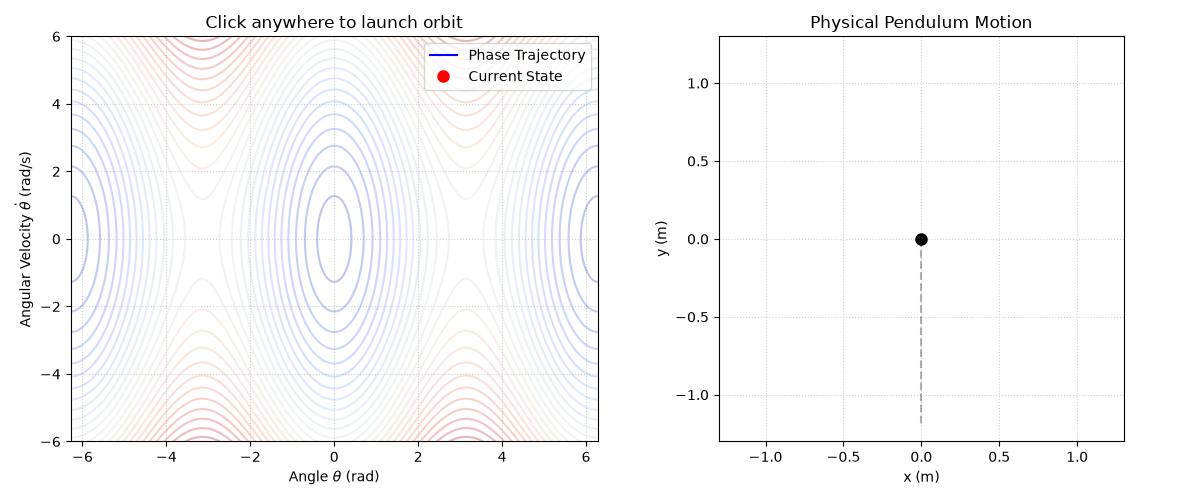

In [1]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from matplotlib.animation import FuncAnimation

# 1. CRITICAL: Destroy all existing figures and stop their active background animations
plt.close('all')

# Pendulum parameters
g, L = 9.81, 1.0

def pendulum(t, y):
    theta, omega = y
    return [omega, -(g / L) * np.sin(theta)]

# Create side-by-side figure layout
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# ----------------------------------------------------
# 1. Left Plot: Phase Space Portrait
# ----------------------------------------------------
theta_grid = np.linspace(-2 * np.pi, 2 * np.pi, 300)
omega_grid = np.linspace(-6, 6, 300)
THETA, OMEGA = np.meshgrid(theta_grid, omega_grid)
E = 0.5 * OMEGA**2 - (g / L) * np.cos(THETA)

ax1.contour(THETA, OMEGA, E, levels=30, cmap='coolwarm', alpha=0.35)
traj_line, = ax1.plot([], [], 'b-', lw=1.5, label='Phase Trajectory')
phase_point, = ax1.plot([], [], 'ro', ms=8, label='Current State')

ax1.set_title("Click anywhere to launch orbit")
ax1.set_xlabel(r"Angle $\theta$ (rad)")
ax1.set_ylabel(r"Angular Velocity $\dot{\theta}$ (rad/s)")
ax1.set_xlim(-2 * np.pi, 2 * np.pi)
ax1.set_ylim(-6, 6)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right')

# ----------------------------------------------------
# 2. Right Plot: Physical Pendulum
# ----------------------------------------------------
ax2.plot([0], [0], 'ko', ms=8, zorder=5)                 # Pivot point
ax2.plot([0, 0], [0, -1.2 * L], 'k--', alpha=0.3)        # Vertical equilibrium axis
rod_line, = ax2.plot([], [], 'k-', lw=3)                  # Pendulum rod
bob_point, = ax2.plot([], [], 'ro', ms=16, zorder=4)      # Pendulum bob

ax2.set_title("Physical Pendulum Motion")
ax2.set_xlim(-1.3 * L, 1.3 * L)
ax2.set_ylim(-1.3 * L, 1.3 * L)
ax2.set_aspect('equal')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.set_xlabel("x (m)")
ax2.set_ylabel("y (m)")

anim = None

def onclick(event):
    global anim
    if event.inaxes != ax1 or event.xdata is None or event.ydata is None:
        return
    
    # Extract initial conditions from click
    theta0, omega0 = event.xdata, event.ydata
    
    # Solve trajectory
    t_eval = np.linspace(0, 10, 200)
    sol = solve_ivp(pendulum, (0, 10), [theta0, omega0], t_eval=t_eval)
    
    theta_vals, omega_vals = sol.y[0], sol.y[1]
    x_vals = L * np.sin(theta_vals)
    y_vals = -L * np.cos(theta_vals)
    
    def update(frame):
        traj_line.set_data(theta_vals[:frame], omega_vals[:frame])
        phase_point.set_data([theta_vals[frame]], [omega_vals[frame]])
        rod_line.set_data([0, x_vals[frame]], [0, y_vals[frame]])
        bob_point.set_data([x_vals[frame]], [y_vals[frame]])
        return traj_line, phase_point, rod_line, bob_point

    # Safely stop existing animation loop before starting a new one
    if anim is not None:
        try:
            anim.event_source.stop()
        except Exception:
            pass
        
    anim = FuncAnimation(fig, update, frames=len(t_eval), interval=30, blit=True, repeat=True)
    fig.canvas.draw_idle()

# Attach mouse listener
fig.canvas.mpl_connect('button_press_event', onclick)

plt.tight_layout()
plt.show()

## Kapitza Pendulum